In [ ]:
# =====================================================================
# 1. ENVIRONMENT SETUP, REPRODUCIBILITY & FILE PATH CONFIGURATION
# =====================================================================

# Mount Google Drive to load dataset and save checkpoint files
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import random, json, os, shutil, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set a global seed across all libraries to ensure reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Define the main Insight Hunters project directory
Insight_hunters_root1 = Path(
    '/content/drive/MyDrive/Insight_Hunters_Project'
)

# Existing verified physical dataset split
Data_Split_Root = Insight_hunters_root1 / "02_Data_Splits"

Train_Dir = Data_Split_Root / "train"
VAL_DIR = Data_Split_Root / "val"

# Save the FINAL standardized EfficientNetB0 run separately.
# This preserves Solethu's previous EfficientNetB0 results.
Out_DIR = (
    Insight_hunters_root1
    / "03_Model_Checkpoints"
    / "EfficientNetB0_Final"
)

# Create the output directory if it does not already exist
Out_DIR.mkdir(parents=True, exist_ok=True)

# Target configurations for model training
Img_size = (224, 224)
Batch_Size = 32

Expected_classes = [
    "tb_negative",
    "tb_positive"
]

# Hardware Check: Confirm if a GPU is available
gpus = tf.config.list_physical_devices("GPU")

print("=" * 65)
print("EfficientNetB0 - Environment check")
print("=" * 65)

if gpus:
    print("GPU detected:   Yes")
    print(f"GPU device: {gpus[0].name}")
else:
    print("GPU detected:   No")

print("Tensorflow version:", tf.__version__)

# Stage 1 best-checkpoint location for this FINAL standardized run
CKPT_INIT = str(Out_DIR / "best_stage1_frozen.keras")

# Standardized Stage 1 maximum epoch budget
MAX_INITIAL_EPOCHS = 25

print("\nPaths configured successfully.")
print("Training data:", Train_Dir)
print("Validation data:", VAL_DIR)
print("Final EfficientNet outputs:", Out_DIR)
print("Stage 1 checkpoint:", CKPT_INIT)

Mounted at /content/drive
EfficientNetB0 - Environment check
GPU detected:   Yes
GPU device: /physical_device:GPU:0
Tensorflow version: 2.21.0

Paths configured successfully.
Training data: /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits/train
Validation data: /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits/val
Final EfficientNet outputs: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final
Stage 1 checkpoint: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage1_frozen.keras


In [ ]:
# =====================================================================
# 2. RAW IMAGE DATASET LOADING FROM DIRECTORIES
# =====================================================================

# Get file lists to identify class sizes
train_counts, val_counts = os.listdir(Train_Dir), os.listdir(VAL_DIR)
train_total = len(train_counts)
val_total = len(val_counts)

# Load the training raw images from subdirectories, auto-inferring label mappings
train_raw = keras.utils.image_dataset_from_directory(
    Train_Dir,
    labels="inferred",
    label_mode="binary",
    color_mode="rgb",
    batch_size=Batch_Size,
    image_size=Img_size,
    shuffle=True,       # Shuffling is vital during training to avoid ordering bias
    seed=SEED,
)

# Load the validation raw images without shuffling to keep evaluations stable
val_raw = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    color_mode="rgb",
    batch_size=Batch_Size,
    image_size=Img_size,
    shuffle=False,      # Shuffle must be disabled for logical evaluation maps
    seed=SEED,
)

# Display the integer-to-class mapping outputted by the generator
print("Class mapping:\t", dict(enumerate(train_raw.class_names)))

Found 560 files belonging to 2 classes.
Found 120 files belonging to 2 classes.
Class mapping:	 {0: 'tb_negative', 1: 'tb_positive'}


In [ ]:
# =====================================================================
# 3. PIPELINE PREPROCESSING & SHARED DATA AUGMENTATION
# =====================================================================

from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.applications import EfficientNetB0

# Configuration log of the augmentations applied to images
Augmentation_config = {
    "RandomRotation": "factor=5/360 (approximately +/- 5 degrees)",
    "RandomTranslation": "height_factor=0.05, width_factor=0.05",
    "RandomZoom": "height_factor=(-0.10, 0.10), width_factor=(-0.10, 0.10)",
    "RandomContrast": "factor=0.10",
    "HorizontalFlip": "Disabled",
    "VerticalFlip": "Disabled",
    "AppliedTo": "Training data only"
}

# Augmentation sequential block to help prevent overfitting during training
augment = keras.Sequential([
    layers.RandomRotation(factor = 5/360, seed=SEED),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05, seed=SEED),
    layers.RandomZoom(height_factor=(-0.10, 0.10)),
    layers.RandomContrast(factor=0.10, seed=SEED)
], name="shared_data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE

# Apply augmentation first (training=True) then model-specific scaled preprocessing
train_ds = (train_raw
            .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
            .map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
            .prefetch(buffer_size=AUTOTUNE))

# Validation dataset bypasses augmentation entirely; only scales pixel inputs
val_ds = (val_raw.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
            .prefetch(buffer_size=AUTOTUNE))

# Summary report verifying load specifications
print("\n" + "=" * 65)
print("EfficientNetB0 - DATASET LOADING SUMMARY")
print("=" * 65)
print("Training images:       560")
print("Validation images:     120")
print("Input dimensions:      224 x 224 x 3")
print("Batch size:            32")
print("Class 0:               tb_negative")
print("Class 1:               tb_positive")
print("Training shuffle:      ENABLED")
print("Validation shuffle:    DISABLED")
print("Prefetch:              ENABLED")
print("Test dataset:          NOT LOADED")
print("=" * 65)
print("TRAINING & VALIDATION DATASETS LOADED SUCCESSFULLY")


EfficientNetB0 - DATASET LOADING SUMMARY
Training images:       560
Validation images:     120
Input dimensions:      224 x 224 x 3
Batch size:            32
Class 0:               tb_negative
Class 1:               tb_positive
Training shuffle:      ENABLED
Validation shuffle:    DISABLED
Prefetch:              ENABLED
Test dataset:          NOT LOADED
TRAINING & VALIDATION DATASETS LOADED SUCCESSFULLY


In [ ]:
# =====================================================================
# 4. ARCHITECTURE CONFIGURATION (STAGE 1: FROZEN BASE)
# =====================================================================

# Import the backbone model pre-trained on ImageNet weights without top dense layer
EfficientNetB0_base = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=Img_size + (3,)
)

# Freeze base model layers so features aren't altered during first training stage
EfficientNetB0_base.trainable = False

# Construct Functional API pipeline
inputs = keras.Input(shape=Img_size + (3,))
x = EfficientNetB0_base(inputs, training=False) # Ensure layers act in inference mode
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.5, seed=SEED, name="dropout")(x) # Reduces risk of overfitting
outputs = layers.Dense(1, activation="sigmoid", name="tb_prediction")(x)

model = keras.Model(inputs=inputs, outputs=outputs, name="InsightHunters_EfficientNetB0_TB")

# Reusable function to quickly recompile the model using custom learning rates
def compile_model(lr):
  model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")]
  )

# Initial training with learning rate = 0.0001 (1e-4)
compile_model(1e-4)

# Print structure layout of trainable parameters
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "InsightHunters_EfficientNetB0_TB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tb_prediction (Dense)           │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# =====================================================================
# 5. STAGE 1 TRAINING RUN & MONITORING METRICS
# =====================================================================

CKPT_INIT = f"{Out_DIR}/best_stage1_frozen.keras"
MAX_INITIAL_EPOCHS = 25

# Set callbacks for Early Stopping, Checkpointing, Dynamic Learning Rate reduction, and History Logging
cb_init = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience= 5,
        restore_best_weights=True, # Revert weights to best validation epoch
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=CKPT_INIT,
        save_best_only=True,      # Overwrite only when validation loss decreases
        monitor="val_loss",
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,               # Multiply learning rate by 0.2 when validation loss plateaus
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.CSVLogger(f"{Out_DIR}/stage_1_history.csv") # Log training metrics offline
]

Stg1_start = time.time()

# Fit the model to train datasets with frozen base layer
hist_1 = model.fit(train_ds,
                   validation_data=val_ds,
                   epochs=MAX_INITIAL_EPOCHS,
                   callbacks=cb_init,
                   verbose=1
                   )

Stg1_end = time.time()

# Track execution times and retrieve optimum validation performance values
stg1_duration_sec = (Stg1_end - Stg1_start)
stg1_minutes = stg1_duration_sec / 60

epochs_complete = len(hist_1.history["val_loss"])
best_val_loss = min(hist_1.history["val_loss"])
best_epoch = (np.argmin(hist_1.history["val_loss"]) + 1)
best_val_acc = hist_1.history["val_accuracy"][best_epoch - 1]

Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.4428 - loss: 0.7781
Epoch 1: val_loss improved from None to 0.69273, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage1_frozen.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage1_frozen.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 267s 12s/step - accuracy: 0.4696 - loss: 0.7652 - val_accuracy: 0.5417 - val_loss: 0.6927 - learning_rate: 1.0000e-04
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.4913 - loss: 0.7334
Epoch 2: val_loss improved from 0.69273 to 0.67854, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage1_frozen.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage1_frozen.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 89s

In [ ]:
# Print overall training time and maximum validation performance achieved in Stage 1
print(f"Stage 1 time: {stg1_minutes:.1f} min | best val_loss {min(hist_1.history['val_loss']):.4f}")

Stage 1 time: 37.8 min | best val_loss 0.5646


In [ ]:
# Display the summary containing specific metric points of training Stage 1
print("="*65)
print("Stage 1 training summary")
print("="*65+"\n")

print(f"Epochs completed: {epochs_complete}")
print(f"Best validation loss: {best_val_loss}")
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_acc}")

Stage 1 training summary

Epochs completed: 25
Best validation loss: 0.56461101770401
Best epoch: 25
Best validation accuracy: 0.7250000238418579


In [ ]:
# =====================================================================
# 6. CONFIGURING STAGE 2 FINE-TUNING (UNFREEZING SPECIFIC BLOCKS)
# =====================================================================

# Reload the optimum weights achieved during Stage 1
model = keras.models.load_model(CKPT_INIT)

base = model.get_layer("efficientnetb0")
base.trainable = True

# Lock all backbone base layers by default
for l in base.layers:
  l.trainable = False

# Define conditional rules to selectively unfreeze 'block7a' features
inside_block7a = False
for l in base.layers:
  if l.name.startswith("block7a"):
    inside_block7a = True

  if not inside_block7a:
    continue
      # Batch Normalization statistics must remain frozen to prevent scaling issues
  if not isinstance(l, layers.BatchNormalization):
    l.trainable = True
  else:
    l.trainable = False

# Check list of active layers slated for training updates
unfrozen = [
    l.name for l in base.layers if l.trainable
]

print(f"Unfrozen base layers ({len(unfrozen)}): {unfrozen}")
for name in unfrozen:
  print(name)

# Print count of updated trainable parameters after unfreezing block7a
trainable_param = 0
for w in model.trainable_weights:
  trainable_param += np.prod(w.shape)

trainable_param = int(trainable_param)
print(f"Trainable parameters: {trainable_param:,}")

# Verify index layout and architecture structure for target fine-tuning layers
"""
for i, layer in enumerate(base.layers):
    if "block7a" in layer.name:
        print(i, layer.name, type(layer).__name__)
"""

Unfrozen base layers (12): ['block7a_expand_conv', 'block7a_expand_activation', 'block7a_dwconv', 'block7a_activation', 'block7a_se_squeeze', 'block7a_se_reshape', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_se_excite', 'block7a_project_conv', 'top_conv', 'top_activation']
block7a_expand_conv
block7a_expand_activation
block7a_dwconv
block7a_activation
block7a_se_squeeze
block7a_se_reshape
block7a_se_reduce
block7a_se_expand
block7a_se_excite
block7a_project_conv
top_conv
top_activation
Trainable parameters: 1,122,865


'\nfor i, layer in enumerate(base.layers):\n    if "block7a" in layer.name:\n        print(i, layer.name, type(layer).__name__)\n'

In [ ]:
# =====================================================================
# 7. COMPILING FOR FINE-TUNING WITH HIGH PRECISION ADJUSTMENT
# =====================================================================

MAX_FINE_TUNE_EPOCHS = 15
Stage_1_checkpoint_path = Out_DIR / "best_stage1_frozen.keras"
CKPT_FT = f"{Out_DIR}/best_stage2_finetuned.keras"

# Use a much lower learning rate during fine-tuning to preserve features
FT_LR = 1e-5
compile_model(FT_LR)

# Configure training safety checks and learning-rate updates
cb_ft = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=CKPT_FT,
        save_best_only=True,
        monitor="val_loss",
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# Display newly validated optimizer values
current_lr = float(
    tf.keras.backend.get_value(model.optimizer.learning_rate)
)
print(f"Current learning rate: {current_lr}")

Current learning rate: 9.999999747378752e-06


In [ ]:
# =====================================================================
# 8. EXECUTING STAGE 2 FINE-TUNING PROCESS
# =====================================================================

stg2_start_time = time.time()

# Run model compilation with unfrozen layers
hist_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_FINE_TUNE_EPOCHS,
    callbacks=cb_ft,
    verbose=1
)

stg2_end_time = time.time()

# Package history metrics to construct an incremental stage epoch range
df2 = pd.DataFrame(hist_2.history)
df2.insert(0, "epoch", range(epochs_complete + 1, epochs_complete + len(df2) + 1))
df2.insert(1, "stage", 2)

# Save Stage 2 training tracking values to local CSV
df2.to_csv(f"{Out_DIR}/stage2_history.csv", index=False)

stg2_duration_sec = (stg2_end_time - stg2_start_time)
stg2_minutes = stg2_duration_sec / 60

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6706 - loss: 0.6019
Epoch 1: val_loss improved from None to 0.55829, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage2_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage2_finetuned.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 122s 4s/step - accuracy: 0.6893 - loss: 0.5848 - val_accuracy: 0.7250 - val_loss: 0.5583 - learning_rate: 1.0000e-05
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6821 - loss: 0.6118
Epoch 2: val_loss improved from 0.55829 to 0.54845, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage2_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/EfficientNetB0_Final/best_stage2_finetuned.keras
18/18 ━━━━━━━━━━━━━

In [ ]:
# =====================================================================
# 9. PERFORMANCE MERGE, SELECTION & WEIGHT SAVING RUN
# =====================================================================

print(f"Stage 2 time: {stg2_minutes:.1f} min | best val_loss {min(hist_2.history['val_loss']):.4f}")

# Extract and compare optimum loss achievements from both stages
best1, best2 = min(hist_1.history["val_loss"]), min(hist_2.history["val_loss"])

# Select the stage configuration that achieved the lowest validation loss
final_stage = "stage2_finetuned" if best2 < best1 else "stage1_frozen"
final_src = CKPT_FT if final_stage == "stage2_finetuned" else CKPT_INIT
FINAL_CKPT = f"{Out_DIR}/efficientnetb0_FINAL_best.keras"

# Save a duplicate copy of the best model configuration in local workspace
shutil.copy(final_src, FINAL_CKPT)

print()
print(f"Stage1 best val_loss={best1:.4f} | Stage2 best val_loss={best2:.4f} -> final = {final_stage}")

Stage 2 time: 21.6 min | best val_loss 0.4865

Stage1 best val_loss=0.5646 | Stage2 best val_loss=0.4865 -> final = stage2_finetuned


25 Stage 1 epochs + 15 Stage 2 epochs = 40 total


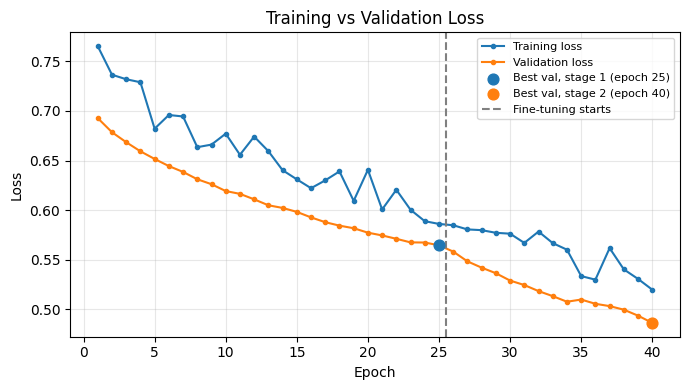

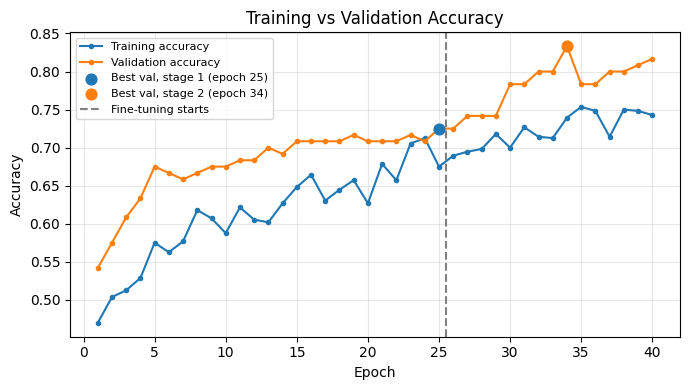

In [ ]:
# =====================================================================
# 10. GENERATING COMPOSITE PERFORMANCE VISUALIZATIONS
# =====================================================================

STAGE1_CSV = f"{Out_DIR}/stage_1_history.csv"
STAGE2_CSV = f"{Out_DIR}/stage2_history.csv"

# Read logs back into dataframe format
df1, df2 = pd.read_csv(STAGE1_CSV), pd.read_csv(STAGE2_CSV)

# Set correct 1-indexed count configurations for Stage 1 epochs
if df1["epoch"].min() == 0:
    df1["epoch"] = df1["epoch"] + 1
df1["stage"] = 1

if df2["epoch"].min() != df1["epoch"].max() + 1:
    print("WARNING: Stage 2 does not start right after Stage 1 - check the epoch columns")

# Combine training metrics of both stages into a single data record
cols = ["epoch", "stage", "accuracy", "val_accuracy", "loss", "val_loss", "learning_rate"]
history = pd.concat([df1[cols], df2[cols]], ignore_index=True)
history.to_csv(f"{Out_DIR}/training_history_combined.csv", index=False)

boundary = df1["epoch"].max() # Epoch location dividing stage 1 and stage 2
print(f"{len(df1)} Stage 1 epochs + {len(df2)} Stage 2 epochs = {len(history)} total")

def plot_comparison(ax, train_col, val_col, ylabel, best="min"):
    """Generates line comparison plots and places labels at optimum stage milestones."""
    ax.plot(history["epoch"], history[train_col], marker="o", ms=3, label=f"Training {ylabel.lower()}")
    ax.plot(history["epoch"], history[val_col],   marker="o", ms=3, label=f"Validation {ylabel.lower()}")

    # Mark peak optimization locations for each individual stage
    for stage, g in history.groupby("stage"):
        row = g.loc[g[val_col].idxmin() if best == "min" else g[val_col].idxmax()]
        ax.scatter(row["epoch"], row[val_col], zorder=5, s=60,
                   label=f"Best val, stage {stage} (epoch {int(row['epoch'])})")

    # Visual divider indicating transition into Stage 2 Fine-Tuning
    ax.axvline(boundary + 0.5, ls="--", c="grey", label="Fine-tuning starts")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(f"Training vs Validation {ylabel}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

# ---- Plot Validation and Training Loss ----
fig, ax = plt.subplots(figsize=(7, 4))
plot_comparison(ax, "loss", "val_loss", "Loss", best="min")
plt.tight_layout()
plt.savefig(f"{Out_DIR}/loss_comparison.png", dpi=150)
plt.show()

# ---- Plot Validation and Training Accuracy ----
fig, ax = plt.subplots(figsize=(7, 4))
plot_comparison(ax, "accuracy", "val_accuracy", "Accuracy", best="max")
plt.tight_layout()
plt.savefig(f"{Out_DIR}/accuracy_comparison.png", dpi=150)
plt.show()